<a href="https://colab.research.google.com/github/sarabenzahra-afk/import_DS/blob/main/data%20pre_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Importing libraries**

**Load and inspect the data**

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

columns = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
]
df=pd.read_csv('https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data',
     names = columns,
     header= None,
     sep = r',\s*',
    engine='python')
df.info()
df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


**Convert dates and inspect types** (there is no colum for dates so i create a column for that)

In [24]:
# Generate random dates
np.random.seed(42)
dates = pd.date_range(start='2000-01-01', periods=len(df), freq='D')
df['date'] = np.random.choice(dates, size=len(df))

# convert
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# inspect data
df.dtypes

,0
age,int64
workclass,object
fnlwgt,int64
education,object
education_num,int64
marital_status,object
occupation,object
relationship,object
race,object
sex,object


**Detect missing values**

In [27]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,0
relationship,0
race,0
sex,0


In [28]:
df.duplicated().sum()


np.int64(0)

**Create a Salary colomn with missing values and duplicates** (there is no  missing values in the original data so I tried to create a column 'salary' with 15% of missing values and i added some duplicates too)

In [32]:
np.random.seed(0)
df['salary'] = np.random.randint(10000, 100000, size=len(df))

# Add ~15% of missing values
missing_idx = np.random.choice(df.index, size=int(len(df) * 0.15), replace=False)
df.loc[missing_idx, 'salary'] = np.nan

# Add duplicates
duplicates = df.sample(n=100, random_state=42)
df = pd.concat([df, duplicates], ignore_index=True)

In [54]:
#count missing values
missing = df.isnull().sum()
missing.sum()

np.int64(4883)

In [62]:
# show raws with missing salary
df[df["salary"].isnull()]

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,salary
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,NaN
17,32,Private,186824,HS-grad,9,Never-married,Machine-op-inspct,Unmarried,White,Male,0,0,40,United-States,<=50K,NaN
18,38,Private,28887,11th,7,Married-civ-spouse,Sales,Husband,White,Male,0,0,50,United-States,<=50K,NaN
20,40,Private,193524,Doctorate,16,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,60,United-States,>50K,NaN
28,39,Private,367260,HS-grad,9,Divorced,Exec-managerial,Not-in-family,White,Male,0,0,80,United-States,<=50K,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32504,50,Private,208630,Masters,14,Divorced,Sales,Not-in-family,White,Female,0,0,50,United-States,>50K,NaN
32510,39,Private,107302,HS-grad,9,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,45,?,>50K,NaN
32525,81,?,120478,Assoc-voc,11,Divorced,?,Unmarried,White,Female,0,0,1,?,<=50K,NaN
32543,45,Local-gov,119199,Assoc-acdm,12,Divorced,Prof-specialty,Unmarried,White,Female,0,0,48,United-States,<=50K,NaN


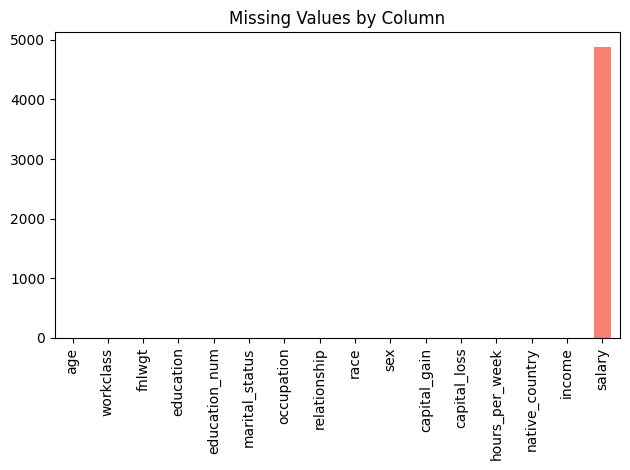

In [57]:
# Plot missing values
missing.plot(kind='bar',title='Missing Values by Column', color='salmon')
plt.tight_layout()
plt.show()

In [60]:
df.duplicated().sum() #count

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)  # Remove

**Detecting Outliers**

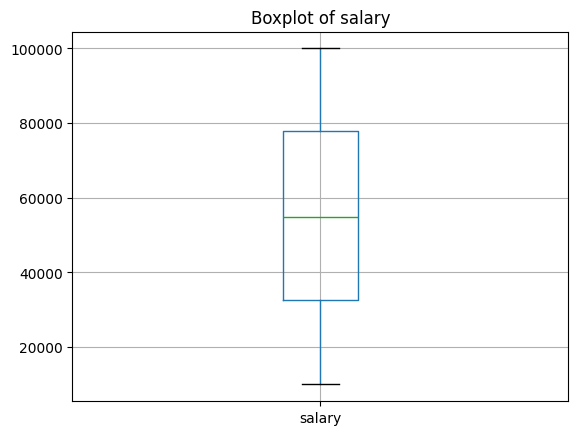

In [87]:
df.boxplot(column='salary')
plt.title("Boxplot of salary")
plt.show()

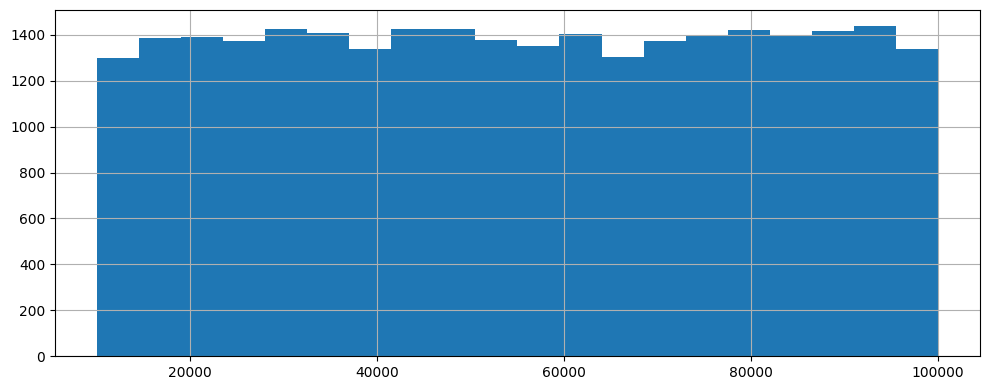

In [86]:
df['salary'].hist(bins=20,figsize=(10,4))
plt.tight_layout()
plt.show()

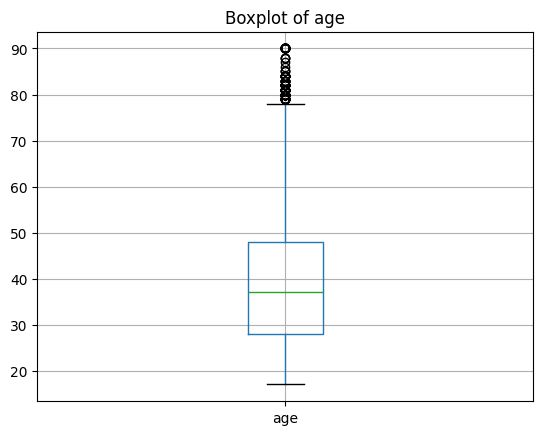

In [95]:
df.boxplot(column='age')
plt.title("Boxplot of age")
plt.show()

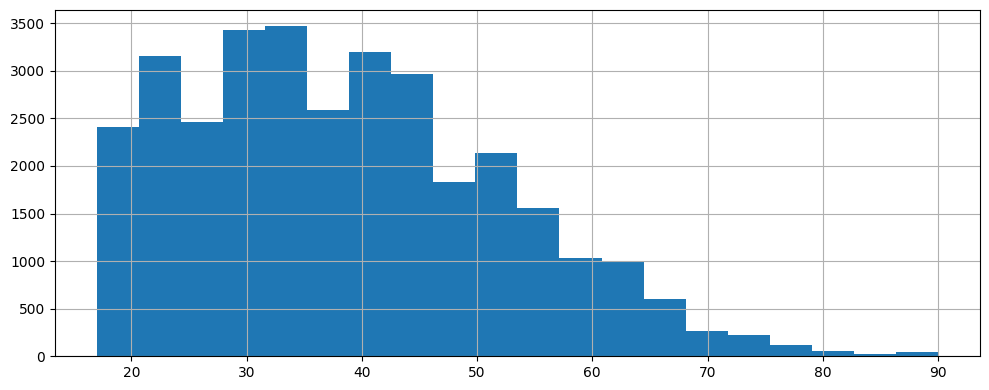

In [92]:
df['age'].hist(bins=20,figsize=(10,4))
plt.tight_layout()
plt.show()

**Cleaning**

In [97]:
# For Cleaning I focused only on the employed population and the outliers helped me to do this segmentation

df.loc[df['age'] > 65, 'age'] = None

**Summary**

In [99]:
df.describe(include='all')

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,salary
count,32560.000000,32560,3.256000e+04,32560,32560.000000,32560,32560,32560,32560,32560,32560.000000,32560.000000,32560.000000,32560,32560,27677.000000
unique,NaN,9,NaN,16,NaN,7,15,6,5,2,NaN,NaN,NaN,42,2,NaN
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K,NaN
freq,NaN,22695,NaN,10501,NaN,14976,4140,13193,27815,21790,NaN,NaN,NaN,29169,24719,NaN
mean,38.581419,NaN,1.897801e+05,NaN,10.080682,NaN,NaN,NaN,NaN,NaN,1077.681941,87.306511,40.437469,NaN,NaN,55140.543231
std,13.640580,NaN,1.055511e+05,NaN,2.572760,NaN,NaN,NaN,NaN,NaN,7385.403083,402.966116,12.347618,NaN,NaN,25936.853378
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN,10002.000000
25%,28.000000,NaN,1.178242e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN,32645.000000
50%,37.000000,NaN,1.783630e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN,54972.000000
75%,48.000000,NaN,2.370545e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN,77783.000000
